# 05 · Stage 5: M3, regimes, regressions, placebo, robustness (spec §7–§8)

**Status:** Stage 5 gate passed on 21 Oct 2026. The decisions (spec #18–#20) are applied here and the tables re-run, with the Stage 6 chart-gate changes (21 Oct): DV01 at the T-1 model yield, the T-10 → T-1 robustness window, the M3 total move T-10 → T+1, and the own-regime placebo as a labelled robustness check. The report charts are in notebook 06.

**What this stage delivers**
1. **Bond-level evidence (decision #17).**
   - **M3**: the auctioned gilt's residual (market yield − model yield) from T-10 to T+10, with the same three numbers.
   - **M1b** extended back to 1999.
   - Before 25 Nov 2002 the DMO published no yields, so the market yield is computed with our pricer from the DMO **clean price** plus our accrued interest. It reproduces the DMO yields 2003–2017 to 0.0001bp (§1).
2. **Control C** for M2: the change in the gilt − OIS spread at the gilt's maturity, for auctions from Dec 2021 (`ois.py`).
3. **Inference** (`inference.py`, `placebo.py`).
   - **The three numbers lead with the placebo-centred p-value** (decision #20).
   - Standard errors clustered by auction week are shown alongside, with Newey-West in calendar time (30-day Bartlett) as a check. Both reproduce statsmodels exactly (`tests/test_stage5.py`).
4. **Regressions** per spec §8 and decision #19 (`analysis.py`), in two specifications.
   - **Ex-ante:** only what is known before bidding (DV01, volatility to T-1, bucket, new issue, supply and QE/QT weeks, regime). Run for every dependent variable.
   - **Auction-outcome:** ex-ante plus cover surprise and tail. **Never for the pre windows.**
   - Dependent variables: M1b (1999–2017); M1 with **gilt fixed effects** (2018–2026); M2 (B-β) three numbers; M3 three numbers; M1 pooled on the M1b sample. H4 is an extra specification.
5. **Placebo** (`placebo.py`): 1,000 draws of non-auction dates for the same gilt in the same bucket (decision #18).
   - M2 and M3 are recomputed exactly; the engine reproduces the real auctions to < 1e-8.
   - Each M3 window is drawn on its own sample.
   - The mean placebo paths are kept for the report's path chart.
   - A second design, with placebo dates in the auction's own regime, is reported for the regime rows only (Stage 6 gate question).
6. **Robustness:**
   - sample drops: LDI window; Feb–Oct 2022; > 5y beyond the curve;
   - controls B and C;
   - regressor variants: DV01 incl. PAOF; volatility at 10y; conventional-only supply; **supply counts**; **cover surprise vs the previous 10**;
   - looser M1b rules.

**Decisions applied (spec #18–#20, 21 Oct 2026)**
- **Approved defaults (#18):** cover surprise vs the previous 5 auctions in the bucket (10 as robustness); H4 from 1 Nov 2022; Newey-West bandwidth 30 calendar days; the placebo design; OIS flat-forward beyond 25y.
- **Supply controls (#18):** dummies, with counts as robustness.
- **Two specifications (#19):** ex-ante and auction-outcome. Cover and tail never enter the pre-window regressions.
- **#20:**
  - The LDI dummy is reported, not interpreted.
  - M3 attenuation is recorded as a limitation, with no refit.
  - Inference leads with the placebo-centred p-value.

Signs: every number is a yield change in bp. **Positive = the gilt cheapened** (its yield rose against the curve or control).

In [1]:
import datetime as dt
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import seaborn as sns

from gilt_study import analysis as an, auctions as au, inference as inf, measures as ms, ois, placebo as pl, plotting

warnings.filterwarnings("ignore")
pd.set_option("display.width", 230); pd.set_option("display.max_rows", 300); pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 60)
plotting.set_seaborn_theme()
A = an.dataset()
OUT = an.main()            # writes data/processed_data/stage5/*.csv
print(f"{len(A)} auctions; M1b {A.m1b_bp.notna().sum()}, M3 (day) {A.m3_day_bp.notna().sum()}, control C (day) {A.m2_day_c_bp.notna().sum()}")

912 auctions; M1b 319, M3 (day) 417, control C (day) 241


## 1. Market yields before Nov 2002, M1b back to 1999, and M3 coverage

In [2]:
P = au.load_auction_panel()
MY = ms.load_market_yields()
print(MY.yield_source.value_counts().to_string(), "\nfrom-clean dates:", MY.loc[MY.yield_source == ms.SRC_FROM_CLEAN, "date"].min(),
      "to", MY.loc[MY.yield_source == ms.SRC_FROM_CLEAN, "date"].max())
# check the method where the DMO did publish yields: the yield from the DMO clean price vs the DMO yield
T = P.groupby("isin").agg(maturity=("maturity", "first"), coupon=("coupon", "first"), fi=("first_issue", "first"), fc=("first_coupon", "first"))
S = MY[(MY.yield_source == ms.SRC_DMO_YIELD) & (MY.dmo_yield > 0)].sample(3000, random_state=1)
dd = lambda v: v if isinstance(v, dt.date) else None
got = ms._yields_from_clean(([(i, d, float(c), T.at[i, "maturity"], T.at[i, "coupon"], dd(T.at[i, "fi"]), dd(T.at[i, "fc"]))
                              for i, d, c in zip(S["isin"], S["date"], S["clean"])],))
diff = 100 * (np.array([g[2] for g in got]) - S["dmo_yield"].to_numpy())
print(f"\nyield from DMO clean price - DMO yield, 3,000 random gilt-days 2002-2017: max |diff| {np.nanmax(np.abs(diff)):.5f} bp")
M = ms.load_measures()
print("\nM1b:", int(M.m1b_bp.notna().sum()), "auctions; earliest", M.loc[M.m1b_bp.notna(), "auction_date"].min())
print("M3 three numbers available:", M[["m3_pre_bp", "m3_day_bp", "m3_post_bp"]].notna().sum().to_dict(),
      "(the series ends 21 Jul 2017)")
ni = A[(A.new_issue == 1) & A.to_2017]
print(f"new issues to Jul 2017: {len(ni)}; with an M3 pre number: {ni.m3_pre_bp.notna().sum()} "
      f"(the DMO reference prices carry the when-issued line at T-6), day {ni.m3_day_bp.notna().sum()}, post {ni.m3_post_bp.notna().sum()}")

yield_source
DMO yield               100328
from DMO clean price      4454 
from-clean dates: 1998-11-02 to 2002-11-22



yield from DMO clean price - DMO yield, 3,000 random gilt-days 2002-2017: max |diff| 0.00006 bp

M1b: 319 auctions; earliest 1999-05-26
M3 three numbers available: {'m3_pre_bp': 395, 'm3_day_bp': 417, 'm3_post_bp': 416} (the series ends 21 Jul 2017)
new issues to Jul 2017: 50; with an M3 pre number: 28 (the DMO reference prices carry the when-issued line at T-6), day 50, post 49


- **The clean-price method is exact where it can be checked.** Where the DMO did publish yields, our pricer reproduces them from the DMO clean price to 0.0001bp.
- **M1b grows from 309 to 319 auctions** (back to 26 May 1999).
- **M3 covers about 400 auctions, 1999–2017.** The pre-auction number needs a price at T-6.
  - For a new issue that exists only when the DMO reference prices carry the when-issued line by then: 28 of the 50 new issues to Jul 2017.
  - When-issued lines are priced for settlement on the issue date (decision #10).
  - *Correction:* the Stage 5 gate notes said new issues have no pre number. That was wrong.

## 2. The headline: the PM's three numbers

**Lead p-value: placebo-centred** (decision #20), with `n placebo` = auctions with an eligible placebo date. The clustered and Newey-West p-values are alongside, and the 95% CI uses the clustered SE. M2 covers all years; M3 and M1b run to 2017 (bond prices). M1b has no placebo analogue, because the AAY exists only on auction days, so its lead p is the clustered one.

In [3]:
H = OUT["headline"]
def show(set_, by):
    t = H[(H["set"] == set_) & (H["by"] == by)].copy()
    t["mean (bp)"] = t["mean_bp"].map("{:+.2f}".format)
    t["95% CI"] = [f"[{m - 1.96 * s:+.2f}, {m + 1.96 * s:+.2f}]" for m, s in zip(t.mean_bp, t.se_cluster)]
    t["lead p"] = [("< 0.001" if p < 0.001 else f"{p:.3f}") + ("" if s == "placebo-centred" else " (cl.)")
                   for p, s in zip(t.lead_p, t.lead_p_source)]
    cols = ["group", "measure", "n", "mean (bp)", "95% CI", "lead p", "n_placebo", "p_placebo_same_regime", "p_cluster",
            "p_nw", "clusters"]
    t = t[cols].rename(columns={"n_placebo": "n placebo", "p_cluster": "p clustered", "p_nw": "p Newey-West",
                                "p_placebo_same_regime": "p placebo, own-regime dates (robustness*)"})
    return t.round(3)
show("M2 (B-β), all years", "all")

,group,measure,n,mean (bp),95% CI,lead p,n placebo,"p placebo, own-regime dates (robustness*)",p clustered,p Newey-West,clusters
0,all,pre,912.0,+0.43,"[+0.10, +0.77]",0.008,897.0,0.001,0.012,0.006,723.0
1,all,day,912.0,+0.04,"[-0.12, +0.19]",0.345,897.0,0.199,0.634,0.627,723.0
2,all,post,912.0,-0.43,"[-0.74, -0.13]",0.074,897.0,0.014,0.006,0.003,723.0
3,all,pre10,912.0,+0.28,"[-0.17, +0.73]",0.215,897.0,0.001,0.231,0.220,723.0


- **\*Own-regime placebo:** a robustness check added after seeing the results (chart gate, 21 Oct 2026).
- **Rows `pre10` and `total`:** added after seeing chart 1 (chart gate, 21 Oct 2026).
  - `pre10` = T-10 → T-1, a robustness pre-auction window for M2 and M3.
  - `total` = the M3 move T-10 → T+1.
- **M2 vs M3 on pre10.** The M2 pre10 number (+0.28bp, placebo p 0.215) is smaller than the main pre number. The M2 path falls from T-10 to T-7 before it rises. The M3 pre10 number (+0.60bp, p < 0.001) is larger than the main pre number, because the bond starts to cheapen around T-8 (chart 1).

In [4]:
show("M2 (B-β), all years", "bucket")

,group,measure,n,mean (bp),95% CI,lead p,n placebo,"p placebo, own-regime dates (robustness*)",p clustered,p Newey-West,clusters
4,short,pre,324.0,+0.45,"[-0.42, +1.31]",0.249,321.0,0.078,0.310,0.276,315.0
5,short,day,324.0,+0.15,"[-0.23, +0.52]",0.250,321.0,0.085,0.451,0.462,315.0
6,short,post,324.0,-0.68,"[-1.40, +0.05]",0.198,321.0,0.040,0.068,0.060,315.0
7,medium,pre,289.0,+0.36,"[-0.05, +0.76]",0.053,277.0,0.070,0.084,0.088,288.0
8,medium,day,289.0,+0.03,"[-0.16, +0.22]",0.359,277.0,0.316,0.753,0.721,288.0
9,medium,post,289.0,-0.31,"[-0.70, +0.08]",0.494,277.0,0.601,0.122,0.113,288.0
10,long,pre,299.0,+0.48,"[+0.04, +0.92]",0.004,299.0,0.001,0.032,0.022,297.0
11,long,day,299.0,-0.08,"[-0.27, +0.12]",0.297,299.0,0.124,0.453,0.430,297.0
12,long,post,299.0,-0.28,"[-0.67, +0.10]",0.167,299.0,0.168,0.152,0.124,297.0
13,short,pre10,324.0,+0.19,"[-0.97, +1.35]",0.871,321.0,0.089,0.749,0.750,315.0


In [5]:
show("M3, 1999-2017", "all")

,group,measure,n,mean (bp),95% CI,lead p,n placebo,"p placebo, own-regime dates (robustness*)",p clustered,p Newey-West,clusters
32,all,pre,395.0,+0.37,"[+0.18, +0.56]",< 0.001,391.0,0.000,0.000,0.002,361.0
33,all,day,417.0,-0.32,"[-0.43, -0.21]",< 0.001,412.0,0.000,0.000,0.000,381.0
34,all,post,416.0,-0.18,"[-0.31, -0.04]",0.004,412.0,0.001,0.010,0.011,380.0
35,all,pre10,367.0,+0.60,"[+0.38, +0.83]",< 0.001,364.0,0.000,0.000,0.000,336.0
36,all,total,367.0,+0.16,"[-0.06, +0.38]",0.012,364.0,0.028,0.145,0.204,336.0


In [6]:
show("M3, 1999-2017", "bucket")

,group,measure,n,mean (bp),95% CI,lead p,n placebo,"p placebo, own-regime dates (robustness*)",p clustered,p Newey-West,clusters
37,short,pre,127.0,+0.51,"[+0.12, +0.91]",< 0.001,126.0,0.000,0.011,0.027,126.0
38,short,day,137.0,-0.50,"[-0.77, -0.23]",< 0.001,136.0,0.000,0.000,0.001,136.0
39,short,post,136.0,-0.39,"[-0.65, -0.13]",0.001,136.0,0.000,0.004,0.005,135.0
40,medium,pre,122.0,+0.40,"[+0.14, +0.66]",< 0.001,119.0,0.000,0.003,0.002,122.0
41,medium,day,127.0,-0.26,"[-0.42, -0.09]",< 0.001,123.0,0.000,0.003,0.004,127.0
42,medium,post,127.0,-0.27,"[-0.52, -0.02]",0.021,123.0,0.011,0.039,0.038,127.0
43,long,pre,146.0,+0.21,"[-0.10, +0.53]",0.005,146.0,0.017,0.186,0.180,146.0
44,long,day,153.0,-0.22,"[-0.32, -0.11]",0.001,153.0,0.000,0.000,0.000,153.0
45,long,post,153.0,+0.09,"[-0.08, +0.26]",0.234,153.0,0.446,0.317,0.292,153.0
46,short,pre10,117.0,+1.03,"[+0.53, +1.54]",< 0.001,117.0,0.000,0.000,0.000,117.0


In [7]:
show("Levels to 2017", "all")

,group,measure,n,mean (bp),95% CI,lead p,n placebo,"p placebo, own-regime dates (robustness*)",p clustered,p Newey-West,clusters
72,all,M1b,319.0,+1.39,"[+0.96, +1.82]",< 0.001 (cl.),NaN,NaN,0.0,0.0,295.0
73,all,M1 (same auctions),319.0,+1.92,"[+1.26, +2.57]",< 0.001 (cl.),NaN,NaN,0.0,0.0,295.0


In [8]:
show("Levels to 2017", "bucket")

,group,measure,n,mean (bp),95% CI,lead p,n placebo,"p placebo, own-regime dates (robustness*)",p clustered,p Newey-West,clusters
62,short,M1b,98.0,+2.08,"[+1.15, +3.01]",< 0.001 (cl.),NaN,NaN,0.000,0.000,98.0
63,short,M1 (same auctions),98.0,+4.78,"[+3.31, +6.26]",< 0.001 (cl.),NaN,NaN,0.000,0.000,98.0
64,medium,M1b,89.0,+0.93,"[+0.09, +1.77]",0.032 (cl.),NaN,NaN,0.032,0.036,89.0
65,medium,M1 (same auctions),89.0,+1.78,"[+0.78, +2.79]",< 0.001 (cl.),NaN,NaN,0.001,0.001,89.0
66,long,M1b,132.0,+1.19,"[+0.64, +1.75]",< 0.001 (cl.),NaN,NaN,0.000,0.000,132.0
67,long,M1 (same auctions),132.0,-0.12,"[-0.92, +0.68]",0.769 (cl.),NaN,NaN,0.769,0.767,132.0


The report versions of these tables are charts 2 and 3 in notebook 06 (`report_2_by_bucket`, `report_3_by_regime`). Below: the M3 paths by bucket, which the report shows for all auctions only.

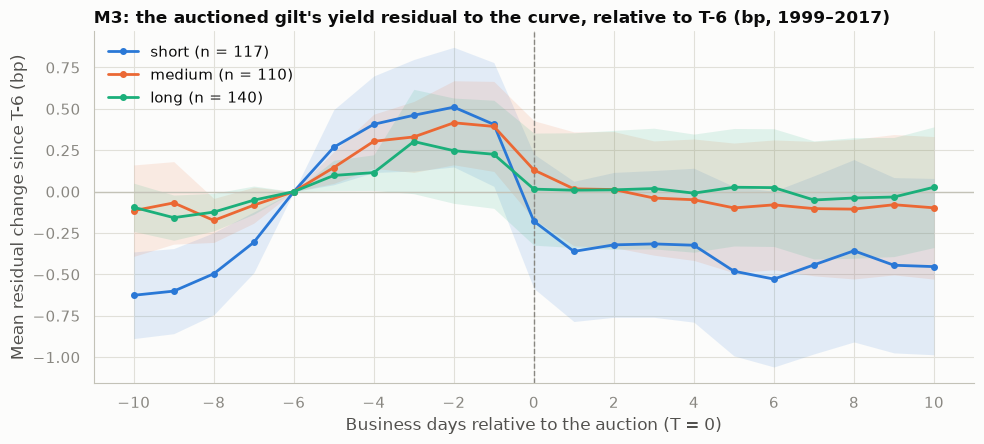

In [9]:
order = an.BUCKETS
cb = plotting.colour_map(order)
M3P = pd.read_csv(ms.M3_PATHS_FILE).merge(A[["auction_id", "bucket"]], on="auction_id")
M3P = M3P[M3P.groupby("auction_id")["residual_bp"].transform(lambda s: s.notna().all())]     # full paths only
agg = M3P.groupby(["bucket", "k"])["residual_rel_t6_bp"].agg(mean="mean", se=lambda s: s.std() / np.sqrt(len(s)), n="size").reset_index()
title = "M3: the auctioned gilt's yield residual to the curve, relative to T-6 (bp, 1999–2017)"
fig_s, ax = plt.subplots(figsize=(10, 4.6))
ax.axhline(0, color=plotting.BASELINE, lw=1); ax.axvline(0, color=plotting.INK_MUTED, lw=1, ls="--")
for b in order:
    a = agg[agg.bucket == b]
    ax.fill_between(a.k, a["mean"] - 1.96 * a.se, a["mean"] + 1.96 * a.se, color=cb[b], alpha=0.12, lw=0)
    ax.plot(a.k, a["mean"], color=cb[b], marker="o", ms=4, label=f"{b} (n = {int(a.n.iloc[0])})")
ax.set_xticks(range(-10, 11, 2)); ax.set_xlabel("Business days relative to the auction (T = 0)")
ax.set_ylabel("Mean residual change since T-6 (bp)"); ax.set_title(title); ax.legend(title=None, loc="upper left")
fig_s.tight_layout()
fig_p = go.Figure()
for b in order:
    a = agg[agg.bucket == b]
    r_, g_, b_ = (int(cb[b][i:i + 2], 16) for i in (1, 3, 5))
    fig_p.add_trace(go.Scatter(x=np.r_[a.k, a.k[::-1]], y=np.r_[a["mean"] + 1.96 * a.se, (a["mean"] - 1.96 * a.se)[::-1]],
                               fill="toself", fillcolor=f"rgba({r_},{g_},{b_},0.12)", line=dict(width=0),
                               hoverinfo="skip", showlegend=False, legendgroup=b))
    fig_p.add_trace(go.Scatter(x=a.k, y=a["mean"], mode="lines+markers", name=f"{b} (n = {int(a.n.iloc[0])})",
                               legendgroup=b, line=dict(color=cb[b]),
                               hovertemplate="T%{x:+d}: %{y:+.2f} bp<extra>" + b + "</extra>"))
fig_p.add_hline(y=0, line_color=plotting.BASELINE); fig_p.add_vline(x=0, line_dash="dash", line_color=plotting.INK_MUTED)
fig_p.update_layout(template=plotting.PLOTLY_TEMPLATE, height=440, title=title, xaxis_title="Business days relative to the auction (T = 0)",
                    yaxis_title="Mean residual change since T-6 (bp)", legend=dict(orientation="h", y=-0.2))
plotting.save_pair("stage5_m3_paths", fig_s, fig_p)
fig_p.show()

**Reading M2 against M3.**
- Both show the gilt cheapening into the auction (pre > 0).
- **They disagree on the day.**
  - M2 day is about zero. The gilt's own yield change, net of β × the far curve, is flat from T-1 to T.
  - M3 day is −0.32bp. On the day, the gilt richens relative to the fitted curve **at its own maturity**.
  - One reading: on auction day the whole sector around the auction maturity moves with the gilt. M3 removes that local move; M2's control (which excludes ±3y) does not.
- **Caveat on M3 (and M1).**
  - The BoE nominal curve is fitted to "conventional dated stocks with a significant amount in issue and having more than three months to maturity" ([BoE, further details about yields data](https://www.bankofengland.co.uk/statistics/details/further-details-about-yields-data)). So the auctioned gilt is itself one of the fitting points.
  - The spline partly follows the gilt's own move. Residual changes are therefore **attenuated towards zero**, more where few gilts sit nearby.
  - M2's control excludes ±3y around the gilt, so M2 does not have this problem.
- In the M3 paths, the short bucket's cheapening starts **before T-6**: −0.6bp at T-10 relative to T-6. The pre number (T-6→T-1) catches only part of it.

## 3. By regime

In [10]:
show("M2 (B-β), all years", "regime")

,group,measure,n,mean (bp),95% CI,lead p,n placebo,"p placebo, own-regime dates (robustness*)",p clustered,p Newey-West,clusters
16,pre-crisis,pre,129.0,+1.13,"[+0.09, +2.16]",0.003,129.0,0.002,0.034,0.009,125.0
17,pre-crisis,day,129.0,-0.05,"[-0.56, +0.46]",0.970,129.0,0.451,0.849,0.833,125.0
18,pre-crisis,post,129.0,-0.88,"[-1.69, -0.07]",0.262,129.0,0.135,0.035,0.058,125.0
19,QE,pre,570.0,+0.59,"[+0.19, +0.98]",0.013,566.0,0.002,0.004,0.003,427.0
20,QE,day,570.0,-0.04,"[-0.21, +0.13]",0.910,566.0,0.666,0.636,0.623,427.0
21,QE,post,570.0,-0.62,"[-0.99, -0.25]",0.016,566.0,0.004,0.001,0.000,427.0
22,LDI stress,pre,3.0,-18.26,"[-43.21, +6.68]",< 0.001,3.0,NaN,0.387,0.001,2.0
23,LDI stress,day,3.0,+0.12,"[-19.44, +19.68]",0.848,3.0,NaN,0.992,0.979,2.0
24,LDI stress,post,3.0,+5.00,"[-9.96, +19.95]",0.107,3.0,NaN,0.631,0.134,2.0
25,active QT,pre,208.0,-0.16,"[-0.80, +0.48]",0.645,199.0,0.688,0.620,0.623,167.0


In [11]:
show("M3, 1999-2017", "regime")

,group,measure,n,mean (bp),95% CI,lead p,n placebo,"p placebo, own-regime dates (robustness*)",p clustered,p Newey-West,clusters
52,pre-crisis,pre,118.0,+0.37,"[+0.13, +0.61]",0.002,118.0,0.000,0.003,0.027,114.0
53,pre-crisis,day,129.0,-0.41,"[-0.59, -0.24]",< 0.001,129.0,0.000,0.000,0.000,125.0
54,pre-crisis,post,129.0,-0.12,"[-0.29, +0.05]",0.320,129.0,0.084,0.171,0.207,125.0
55,QE,pre,277.0,+0.37,"[+0.12, +0.62]",< 0.001,273.0,0.000,0.004,0.019,247.0
56,QE,day,288.0,-0.28,"[-0.42, -0.14]",< 0.001,283.0,0.000,0.000,0.001,256.0
57,QE,post,287.0,-0.20,"[-0.38, -0.02]",0.003,283.0,0.003,0.028,0.026,255.0
58,pre-crisis,pre10,103.0,+0.92,"[+0.50, +1.33]",< 0.001,103.0,0.000,0.000,0.001,100.0
59,pre-crisis,total,103.0,+0.41,"[+0.02, +0.80]",0.014,103.0,0.020,0.042,0.080,100.0
60,QE,pre10,264.0,+0.48,"[+0.22, +0.75]",< 0.001,261.0,0.000,0.000,0.002,236.0
61,QE,total,264.0,+0.07,"[-0.20, +0.33]",0.239,261.0,0.261,0.620,0.657,236.0


**Two placebo designs.**
- **Main design (decision #18; kept at the chart gate).** The placebo date of a QE-era auction can fall in any regime, as long as the gilt and bucket match. The placebo centre therefore pools regimes.
- **Own-regime design: robustness, added after seeing the results.** The date must lie in the auction's own regime. LDI-window auctions get no date under this design, because the window is too short.
- **Largest differences:**
  - regime rows: M2 pre-crisis post (0.262 vs 0.135) and active-QT day (0.030 vs 0.013); no charted marker changes fill;
  - headline: M2 all-auction post (0.074 vs 0.014).

## 4. Control C (gilt − OIS) against B-β, Dec 2021 onwards

In [12]:
RM = OUT["robust_means"]
t = RM[RM.variant.isin(["M2 B-β on the control-C sample (Dec 2021+)", "M2 control C (gilt - OIS, Dec 2021+)"])]
t.pivot_table(index=["group", "measure"], columns="variant", values="mean_bp", sort=False).round(2).join(
    t.pivot_table(index=["group", "measure"], columns="variant", values="p_cluster", sort=False).round(3), rsuffix=" p")

variant         M2 B-β on the control-C sample (Dec 2021+)  M2 control C (gilt - OIS, Dec 2021+)  M2 B-β on the control-C sample (Dec 2021+) p  M2 control C (gilt - OIS, Dec 2021+) p
group  measure                                                                                                                                                                        
all    pre                                           -0.16                                  0.48                                         0.687                                   0.139
       day                                            0.30                                 -0.06                                         0.139                                   0.698
       post                                           0.22                                  0.09                                         0.541                                   0.698
short  pre                                           -0.20                                  0.83                                         0.833                                   0.053
       day                                            0.43                                 -0.12                                         0.325                                   0.554
       post                                           0.16                                 -0.26                                         0.846                                   0.438
medium pre                                           -0.24                                  0.48                                         0.578                                   0.168
       day                                            0.25                                 -0.02                                         0.352                                   0.944
       post                                          -0.15                                  0.20                                         0.690                                   0.542
long   pre                                            0.01                                 -0.14                                         0.987                                   0.872
       day                                            0.17                                 -0.01                                         0.646                                   0.990
       post                                           0.88                                  0.53                                         0.217                                   0.359

## 5. Regressions (spec §8; decisions #17, #19)

Coefficient (clustered SE). Stars use the clustered p-value: *** 1%, ** 5%, * 10%. The placebo does not apply to regression coefficients.
- The base bucket is short. The base regime is pre-crisis, except in the 2018–2026 fixed-effects regression, where it is QE.
- The two post-QT-decision auctions are descriptive only and are left out.
- The LDI dummy is reported, not interpreted (#20).

**5a. Ex-ante specification:** only what is known before bidding. This is the PM's prediction question.

In [13]:
OUT["regressions_ex_ante"]

,M1b (1999-2017),"M1, gilt FE (2018-2026)",M2 pre (B-β),M2 day (B-β),M2 post (B-β),M3 pre,M3 day,M3 post,"M1 pooled, M1b sample"
const,-0.041 (0.968),-3.073 (2.189),+0.315 (0.955),-0.189 (0.382),-0.092 (0.739),-1.818** (0.858),+0.065 (0.225),-0.600** (0.300),+4.281*** (1.267)
dv01,+0.742** (0.336),+1.459*** (0.501),-0.072 (0.222),-0.024 (0.091),-0.261 (0.191),+0.210 (0.245),+0.057 (0.086),+0.122 (0.116),-0.668 (0.529)
vol,+0.457*** (0.135),+0.141* (0.082),+0.176 (0.154),+0.063 (0.064),-0.189 (0.149),+0.418*** (0.111),-0.173*** (0.044),+0.019 (0.051),+0.199 (0.211)
medium,-1.769** (0.756),-0.955 (1.335),+0.011 (0.571),-0.082 (0.244),+0.718 (0.448),-0.378 (0.325),+0.197 (0.177),+0.009 (0.215),-2.379** (1.085)
long,-2.292** (0.927),-3.983** (1.635),+0.129 (0.685),-0.140 (0.315),+1.125* (0.594),-0.497 (0.441),+0.074 (0.227),+0.212 (0.338),-3.323** (1.413)
new_issue,,+0.496 (0.827),+1.060 (0.692),+0.158 (0.343),+0.606 (0.581),+0.442 (0.443),+0.224 (0.246),-0.110 (0.360),
synd_week,-0.860 (0.675),-0.535 (0.476),+0.296 (0.333),+0.095 (0.188),-0.417 (0.326),-0.269 (0.203),-0.055 (0.141),+0.079 (0.185),-1.399 (0.981)
tender_week,+0.442 (0.771),-0.983 (0.603),-0.618 (0.723),-0.300 (0.282),-0.627 (0.506),+0.125 (0.336),+0.107 (0.192),-0.112 (0.260),+1.401 (1.086)
qt_week,,-2.272*** (0.819),+0.240 (0.878),-0.068 (0.335),+0.229 (0.820),,,,
qe_week,-0.198 (0.568),-0.845 (0.693),+0.124 (0.416),-0.108 (0.188),-0.148 (0.353),+0.070 (0.296),-0.026 (0.137),-0.085 (0.173),+0.732 (0.824)


**5b. Auction-outcome specification:** ex-ante + cover surprise + tail, for explanation. Not run for the pre windows (decision #19).

In [14]:
OUT["regressions_outcome"]

,M1b (1999-2017),"M1, gilt FE (2018-2026)",M2 day (B-β),M2 post (B-β),M3 day,M3 post,"M1 pooled, M1b sample"
const,+0.304 (0.959),-3.682* (2.182),-0.252 (0.375),-0.150 (0.728),+0.162 (0.231),-0.498* (0.269),+4.369*** (1.270)
dv01,+0.531* (0.319),+1.723*** (0.522),-0.117 (0.092),-0.248 (0.183),+0.005 (0.083),+0.147 (0.095),-0.762 (0.532)
vol,+0.429*** (0.142),+0.154* (0.079),+0.034 (0.060),-0.183 (0.152),-0.205*** (0.042),+0.074* (0.043),+0.084 (0.221)
medium,-1.569** (0.743),-0.925 (1.323),+0.095 (0.230),+0.675 (0.460),+0.352** (0.173),-0.178 (0.216),-1.905* (1.091)
long,-1.846** (0.889),-4.156** (1.639),+0.064 (0.299),+1.125* (0.629),+0.183 (0.221),+0.106 (0.262),-3.280** (1.459)
new_issue,,+0.540 (0.847),-0.074 (0.337),+0.420 (0.571),+0.033 (0.207),-0.212 (0.250),
synd_week,-0.886 (0.665),-0.510 (0.468),+0.101 (0.188),-0.421 (0.322),-0.064 (0.136),+0.085 (0.179),-1.418 (0.981)
tender_week,+0.475 (0.771),-1.063* (0.610),-0.288 (0.276),-0.567 (0.504),+0.070 (0.174),-0.021 (0.234),+1.337 (1.076)
qt_week,,-2.342*** (0.804),+0.005 (0.349),+0.298 (0.827),,,
qe_week,-0.132 (0.553),-0.988 (0.718),-0.100 (0.180),-0.147 (0.378),-0.022 (0.128),-0.073 (0.162),+0.575 (0.828)


**DV01 is now priced at the T-1 model yield** (chart gate, 21 Oct 2026), so it is known before bidding. Before, it was priced at the AAY, an auction outcome. The two differ little in level (below), but the old one was **mechanically tied to M1**: a higher AAY means a lower DV01. That pulled the DV01 coefficient towards zero in the level regressions. The table compares every DV01 coefficient, and lists every coefficient whose clustered p crosses 5%. The amount is still the D2.1A amount.

In [15]:
from gilt_study.pricing import gilt_price
dd = lambda v: v if isinstance(v, dt.date) else None
d1 = np.array([gilt_price(s, m, c, y / 100.0, dd(fi), dd(fc))["dv01"] for s, m, c, y, fi, fc in
               zip(A.settlement_date, A.maturity, A.coupon, A.model_yield_t1, A.first_issue, A.first_coupon)])
r = d1 / A.dv01_per_100.to_numpy() - 1
print(f"DV01 at the T-1 model yield vs at the AAY: mean |difference| {100 * np.abs(r).mean():.2f}%, max {100 * np.abs(r).max():.1f}%, "
      f"correlation {np.corrcoef(d1, A.dv01_per_100)[0, 1]:.4f}")
new = pd.concat([an.long_table(an.run_specs(A, s)) for s in an.SPECIFICATIONS], ignore_index=True)
old = pd.concat([an.long_table(an.run_specs(A, s, replace={"dv01": "dv01_aay"})) for s in an.SPECIFICATIONS], ignore_index=True)
old["variable"] = old["variable"].replace({"dv01_aay": "dv01"})
cmp_ = new.merge(old, on=["specification", "spec", "variable"], suffixes=(" (T-1)", " (AAY)"))
cols = ["specification", "spec", "variable", "coef (AAY)", "p_cluster (AAY)", "coef (T-1)", "p_cluster (T-1)"]
print("DV01 coefficients:")
display(cmp_[cmp_.variable == "dv01"][cols].round(3))
print("Coefficients whose clustered p crosses 5% with the switch:")
cmp_[(cmp_["p_cluster (AAY)"] < 0.05) != (cmp_["p_cluster (T-1)"] < 0.05)][cols].round(3)

DV01 at the T-1 model yield vs at the AAY: mean |difference| 0.55%, max 6.9%, correlation 0.9998


DV01 coefficients:


,specification,spec,variable,coef (AAY),p_cluster (AAY),coef (T-1),p_cluster (T-1)
1,ex-ante,M1b (1999-2017),dv01,0.613,0.069,0.742,0.028
10,ex-ante,"M1, gilt FE (2018-2026)",dv01,1.024,0.040,1.459,0.004
22,ex-ante,M2 pre (B-β),dv01,-0.064,0.772,-0.072,0.744
35,ex-ante,M2 day (B-β),dv01,-0.031,0.735,-0.024,0.793
48,ex-ante,M2 post (B-β),dv01,-0.266,0.161,-0.261,0.172
61,ex-ante,M3 pre,dv01,0.216,0.386,0.210,0.391
71,ex-ante,M3 day,dv01,0.051,0.557,0.057,0.513
81,ex-ante,M3 post,dv01,0.121,0.294,0.122,0.292
91,ex-ante,"M1 pooled, M1b sample",dv01,-1.048,0.055,-0.668,0.208
100,auction-outcome,M1b (1999-2017),dv01,0.395,0.220,0.531,0.097


Coefficients whose clustered p crosses 5% with the switch:


,specification,spec,variable,coef (AAY),p_cluster (AAY),coef (T-1),p_cluster (T-1)
1,ex-ante,M1b (1999-2017),dv01,0.613,0.069,0.742,0.028
93,ex-ante,"M1 pooled, M1b sample",medium,-2.023,0.063,-2.379,0.029
94,ex-ante,"M1 pooled, M1b sample",long,-2.494,0.078,-3.323,0.019
102,auction-outcome,M1b (1999-2017),medium,-1.440,0.052,-1.569,0.035
103,auction-outcome,M1b (1999-2017),long,-1.559,0.081,-1.846,0.039
179,auction-outcome,"M1 pooled, M1b sample",dv01,-1.158,0.036,-0.762,0.153
182,auction-outcome,"M1 pooled, M1b sample",long,-2.416,0.099,-3.280,0.025


**H4** (spec ⏳): adds long × post-2022 (from 1 Nov 2022) to the M1 fixed-effects and M2 regressions, under both specifications.

In [16]:
OUT["h4_wide"]

ex-ante                                                              auction-outcome                                    
                                                       M1, gilt FE (2018-2026)        M2 pre (B-β)    M2 day (B-β)    M2 post (B-β) M1, gilt FE (2018-2026)       M2 day (B-β)    M2 post (B-β)
const                                                           -2.227 (2.078)      +0.246 (0.943)  -0.151 (0.377)   -0.114 (0.732)          -2.753 (2.077)     -0.206 (0.371)   -0.169 (0.720)
dv01                                                          +1.148** (0.485)      +0.037 (0.243)  -0.083 (0.104)   -0.227 (0.219)       +1.392*** (0.504)    -0.184* (0.104)   -0.220 (0.217)
vol                                                             +0.132 (0.082)      +0.178 (0.154)  +0.062 (0.064)   -0.189 (0.149)         +0.149* (0.078)     +0.034 (0.060)   -0.183 (0.152)
medium                                                          -0.711 (1.267)      -0.111 (0.580)  -0.016 (0.249)   +0.680 (0.431)          -0.670 (1.253)     +0.168 (0.234)   +0.644 (0.450)
long                                                            -1.933 (1.748)      -0.318 (0.821)  +0.102 (0.387)   +0.987 (0.674)          -2.028 (1.760)     +0.335 (0.369)   +1.012 (0.737)
new_issue                                                       +0.655 (0.833)      +1.056 (0.695)  +0.160 (0.343)   +0.605 (0.581)          +0.715 (0.855)     -0.069 (0.338)   +0.418 (0.572)
synd_week                                                       -0.632 (0.478)      +0.294 (0.334)  +0.096 (0.187)   -0.417 (0.326)          -0.613 (0.471)     +0.101 (0.187)   -0.421 (0.322)
tender_week                                                    -1.052* (0.599)      -0.615 (0.724)  -0.301 (0.282)   -0.627 (0.507)         -1.114* (0.603)     -0.287 (0.276)   -0.568 (0.504)
qt_week                                                      -2.156*** (0.788)      +0.216 (0.878)  -0.055 (0.334)   +0.222 (0.821)       -2.202*** (0.773)     +0.022 (0.349)   +0.291 (0.829)
qe_week                                                         -0.903 (0.679)      +0.102 (0.418)  -0.096 (0.190)   -0.154 (0.354)          -1.058 (0.712)     -0.083 (0.182)   -0.154 (0.381)
QE                                                                                  -0.559 (0.701)  +0.093 (0.334)   +0.686 (0.548)                             +0.252 (0.313)   +0.788 (0.531)
LDI: reported, not interpreted (3 auctions in 2 weeks)       +9.083*** (2.008)  -22.889** (10.725)  -1.048 (6.817)   +9.258 (6.287)      +10.165*** (2.019)     -1.214 (6.688)   +9.484 (6.294)
active_QT                                                    +9.054*** (2.443)      -1.768 (1.158)  +0.505 (0.458)  +1.559* (0.937)       +9.403*** (2.392)     +0.636 (0.432)  +1.646* (0.931)
cover_surprise                                                                                                                               +0.957 (0.813)  -1.151*** (0.300)   -0.197 (0.716)
tail                                                                                                                                         -0.736 (0.633)     +0.348 (0.245)   -0.180 (0.262)
long_x_post2022                                               -7.358** (2.862)      +1.032 (0.858)  -0.560 (0.406)   +0.319 (0.955)       -7.507*** (2.895)     -0.611 (0.401)   +0.256 (0.977)
N                                                                          481                 910             910              910                     481                906              906
clusters (weeks)                                                           329                 721             721              721                     329                718              718
R²                                                                       0.724               0.054           0.012            0.028                   0.728              0.052            0.030
fixed effects                          

## 6. Placebo: 1,000 draws of non-auction dates (same gilt, same bucket; decision #18)

In [17]:
PRA = pd.read_csv(pl.OUT_DIR / "placebo_results.csv")
print("engine reproduces the real auctions to (max |diff|):", PRA.engine_check_max_abs.max())
print(PRA.groupby(["design", "measure", "window"]).no_placebo_date.first().unstack().rename_axis(None, axis=1).to_string())
PR = PRA[PRA.design == "main"]
pfmt = lambda p: "< 0.001" if p < 0.001 else f"{p:.3f}"     # 1,000 draws: the smallest attainable p is 0.001
t = PR[["measure", "group", "window", "n_events", "real_mean_bp", "placebo_mean_bp", "placebo_p2_5", "placebo_p97_5"]].round(3)
t["placebo p"] = PR["p_value"].map(pfmt)
t

engine reproduces the real auctions to (max |diff|): 4.995637681304288e-09
                       day  post   pre  pre10  total
design      measure                                 
main        M2 (B-β)  15.0  15.0  15.0   15.0    NaN
            M3         5.0   4.0   4.0    3.0    3.0
same regime M2 (B-β)  25.0  25.0  25.0   25.0    NaN
            M3        12.0  11.0  10.0    7.0    7.0


,measure,group,window,n_events,real_mean_bp,placebo_mean_bp,placebo_p2_5,placebo_p97_5,placebo p
0,M2 (B-β),all,pre,897,0.429,-0.065,-0.443,0.274,0.008
1,M2 (B-β),short,pre,321,0.434,-0.074,-0.984,0.729,0.249
2,M2 (B-β),medium,pre,277,0.363,-0.079,-0.505,0.375,0.053
3,M2 (B-β),long,pre,299,0.484,-0.041,-0.395,0.348,0.004
4,M2 (B-β),pre-crisis,pre,129,1.129,-0.307,-1.238,0.712,0.003
5,M2 (B-β),QE,pre,566,0.583,-0.024,-0.478,0.429,0.013
6,M2 (B-β),LDI stress,pre,3,-18.262,-0.461,-7.268,6.433,< 0.001
7,M2 (B-β),active QT,pre,199,-0.180,-0.016,-0.750,0.690,0.645
8,M2 (B-β),all,day,897,0.030,-0.045,-0.194,0.117,0.345
9,M2 (B-β),short,day,321,0.128,-0.091,-0.466,0.266,0.250


**How to read the placebo.**
- Each draw replaces every real auction with a random non-auction date for the same gilt (same bucket) and recomputes the mean. The bars are 1,000 such means.
- The p-value is the share of draws at least as far from the placebo mean as the real mean.
- **The placebo centre is not zero for M2 (B-β).** The mean is −0.07bp (pre) and −0.11bp (post), because AR = Δy − βΔc has no intercept. Measured against that centre, the M2 post number weakens: p = 0.074 against 0.006 with clustered SEs. By decision #20 the placebo p leads.
- **The M3 placebo distribution is narrow.** Residual changes on ordinary days are much quieter than on auction days, so the real M3 numbers lie far outside it.
- With 1,000 draws, "< 0.001" means no draw was as extreme.

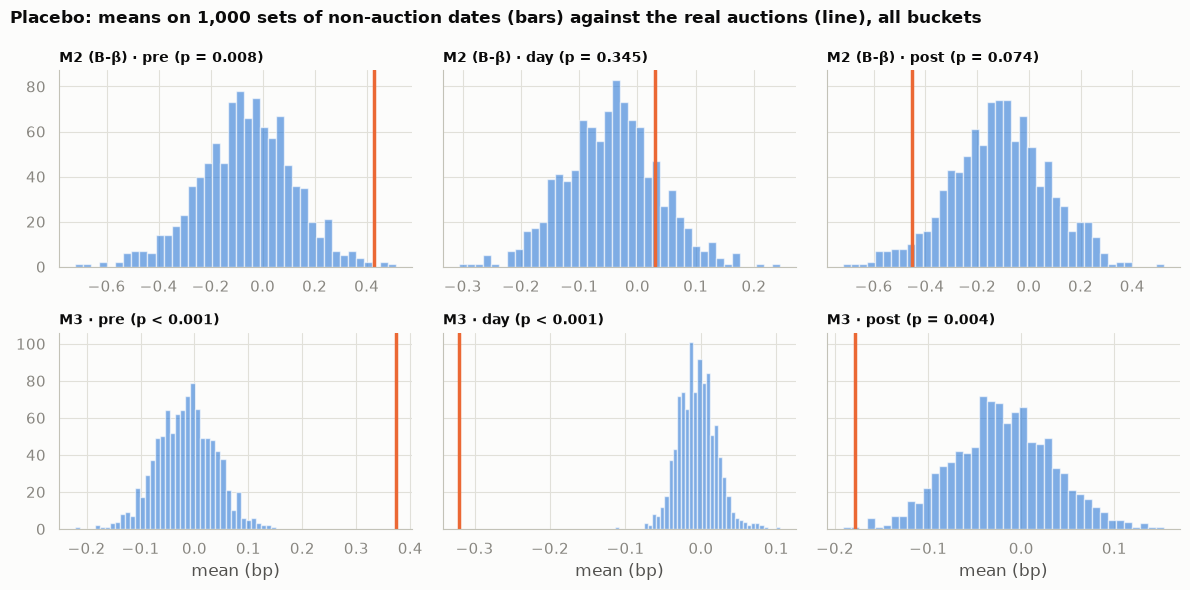

In [18]:
D = pd.read_csv(pl.OUT_DIR / "placebo_draws.csv.gz")
D = D[D.design == "main"]
title = "Placebo: means on 1,000 sets of non-auction dates (bars) against the real auctions (line), all buckets"
cm = plotting.colour_map(["placebo", "real"])
fig_s, axes = plt.subplots(2, 3, figsize=(12, 6), sharey="row")
fig_p = make_subplots(rows=2, cols=3, subplot_titles=[f"{m} · {w}" for m in ["M2 (B-β)", "M3"] for w in an.WINDOWS])
for i, m in enumerate(["M2 (B-β)", "M3"]):
    for j, w in enumerate(an.WINDOWS):
        null = D[(D.measure == m) & (D.group == "all") & (D.window == w)]["mean_bp"]
        real = PR[(PR.measure == m) & (PR.group == "all") & (PR.window == w)]
        ax = axes[i, j]
        ax.hist(null, bins=40, color=cm["placebo"], alpha=0.6)
        ax.axvline(real.real_mean_bp.iloc[0], color=cm["real"], lw=2.5)
        p = real.p_value.iloc[0]
        ax.set_title(f"{m} · {w} (p {'< 0.001' if p < 0.001 else f'= {p:.3f}'})", fontsize=10)
        fig_p.add_trace(go.Histogram(x=null, nbinsx=40, marker_color=cm["placebo"], opacity=0.6, showlegend=False,
                                     hovertemplate="%{x:.2f} bp: %{y} draws<extra>placebo</extra>"), row=i + 1, col=j + 1)
        fig_p.add_vline(x=real.real_mean_bp.iloc[0], line_color=cm["real"], line_width=3, row=i + 1, col=j + 1)
for ax in axes[1]:
    ax.set_xlabel("mean (bp)")
fig_s.suptitle(title, x=0.01, ha="left", fontweight="bold", fontsize=12); fig_s.tight_layout()
fig_p.update_layout(template=plotting.PLOTLY_TEMPLATE, height=560, title=title)
plotting.save_pair("stage5_placebo", fig_s, fig_p)
fig_p.show()

## 7. Robustness

In [19]:
t = RM[RM.group == "all"].copy()
t["cell"] = [f"{m:+.2f} (p {p:.3f})" for m, p in zip(t.mean_bp, t.p_cluster)]
t.pivot_table(index="variant", columns="measure", values="cell", aggfunc="first", sort=False)[["pre", "day", "post", "level"]].fillna("")

measure,pre,day,post,level
variant,,,,
M2 B-β: main,+0.43 (p 0.012),+0.04 (p 0.634),-0.43 (p 0.006),
M2 B-β: drop LDI window,+0.49 (p 0.003),+0.04 (p 0.622),-0.45 (p 0.004),
M2 B-β: drop Feb-Oct 2022 (passive QT),+0.40 (p 0.016),+0.03 (p 0.703),-0.42 (p 0.006),
M2 B-β: drop > 5y beyond the curve,+0.41 (p 0.030),+0.08 (p 0.367),-0.40 (p 0.013),
M2 control B (β = 1),+0.40 (p 0.020),+0.02 (p 0.838),-0.49 (p 0.003),
M2 B-β on the control-C sample (Dec 2021+),-0.16 (p 0.687),+0.30 (p 0.139),+0.22 (p 0.541),
"M2 control C (gilt - OIS, Dec 2021+)",+0.48 (p 0.139),-0.06 (p 0.698),+0.09 (p 0.698),
M3: main,+0.37 (p 0.000),-0.32 (p 0.000),-0.18 (p 0.010),
M3: drop > 5y beyond the curve,+0.41 (p 0.000),-0.33 (p 0.000),-0.26 (p 0.000),


Regression robustness. Key coefficients under every variant: auction-outcome specification first (it carries cover and tail), then ex-ante.

In [20]:
RR = OUT["robust_regressions"]
key = ["dv01", "cover_surprise", "tail", "vol", "QE", "active_QT"]
t = RR[RR.variable.isin(key) & RR.spec.isin(["M1b (1999-2017)", "M1, gilt FE (2018-2026)", "M2 day (B-β)", "M3 day"])
       & (RR.specification == "auction-outcome")].copy()
t["cell"] = [f"{c:+.2f}{'***' if p < .01 else '**' if p < .05 else '*' if p < .1 else ''}" for c, p in zip(t.coef, t.p_cluster)]
t.pivot_table(index=["spec", "variable"], columns="variant", values="cell", aggfunc="first", sort=False)

variant                                     main DV01 incl. PAOF volatility at 10y conventional-only syndications/tenders supply counts (not dummies) cover surprise vs previous 10 drop LDI window drop Feb-Oct 2022  \
spec                    variable                                                                                                                                                                                        
M1b (1999-2017)         dv01              +0.53*           +0.38            +0.55*                                 +0.56*                       +0.52                         +0.54          +0.53*            +0.53*   
                        vol             +0.43***        +0.43***           +0.38**                               +0.44***                    +0.42***                      +0.43***        +0.43***          +0.43***   
                        QE              -1.72***        -1.75***          -1.94***                               -1.91***                    -1.73***                      -1.71***        -1.72***          -1.72***   
                        cover_surprise   -1.48**        -1.56***           -1.53**                                -1.46**                     -1.48**                       -1.25**         -1.48**           -1.48**   
                        tail               +0.07           +0.07             +0.04                                  +0.08                       +0.06                         +0.09           +0.07             +0.07   
M1, gilt FE (2018-2026) dv01            +1.72***         +0.87**          +1.72***                               +1.71***                    +1.72***                      +1.64***        +1.73***          +1.66***   
                        vol               +0.15*           +0.13           +0.23**                                +0.16**                      +0.15*                        +0.16*         +0.19**             +0.18   
                        cover_surprise     +1.14           +0.72             +1.09                                  +1.09                       +1.02                         +0.53           +1.12             +0.87   
                        tail               -0.59           -0.49             -0.54                                  -0.60                       -0.64                         -0.71           -0.38             -0.48   
                        active_QT       +6.52***        +6.20***          +6.51***                               +6.26***                    +6.57***                      +6.53***        +6.42***             +4.59   
M2 day (B-β)            dv01               -0.12           -0.11             -0.13                                  -0.11                       -0.12                         -0.12           -0.11             -0.10   
                        vol                +0.03           +0.04             -0.03                                  +0.04                       +0.03                         +0.04           -0.01             +0.04   
                        QE                 +0.23           +0.25             +0.28                                  +0.24                       +0.22                         +0.24           +0.26             +0.21   
                        cover_surprise  -1.12***        -1.11***          -1.06***                               -1.10***                    -1.13***                      -1.09***        -1.13***          -1.08***   
                        tail               +0.36           +0.35             +0.42                                  +0.36                       +0.35                         +0.36           +0.26             +0.33   
                        active_QT          +0.49           +0.51             +0.51                                  +0.57                       +0.46                         +0.50           +0.52             +0.33   
M3 day                  dv01               +0.00           +0.02             -0.02            

In [21]:
key = ["dv01", "vol", "long", "new_issue", "synd_week", "tender_week", "QE", "active_QT"]
t = RR[RR.variable.isin(key) & (RR.specification == "ex-ante")
       & RR.spec.isin(["M1b (1999-2017)", "M1, gilt FE (2018-2026)", "M2 pre (B-β)", "M3 pre", "M3 day"])].copy()
t["cell"] = [f"{c:+.2f}{'***' if p < .01 else '**' if p < .05 else '*' if p < .1 else ''}" for c, p in zip(t.coef, t.p_cluster)]
t.pivot_table(index=["spec", "variable"], columns="variant", values="cell", aggfunc="first", sort=False)

variant                                  main DV01 incl. PAOF volatility at 10y conventional-only syndications/tenders supply counts (not dummies) drop LDI window drop Feb-Oct 2022 drop > 5y beyond the curve
spec                    variable                                                                                                                                                                               
M1b (1999-2017)         dv01          +0.74**          +0.55*           +0.77**                                +0.77**                     +0.73**         +0.74**           +0.74**                    +0.96**
                        vol          +0.46***        +0.46***          +0.40***                               +0.47***                    +0.45***        +0.46***          +0.46***                   +0.41***
                        long          -2.29**         -1.93**          -2.58***                                -2.23**                     -2.26**         -2.29**           -2.29**                    -2.64**
                        synd_week       -0.86           -0.85             -0.82                                  -0.28                       -0.85           -0.86             -0.86                      -0.94
                        tender_week     +0.44           +0.45             +0.70                                  +0.60                       +0.54           +0.44             +0.44                      +0.64
                        QE           -1.82***        -1.88***          -2.05***                               -2.00***                    -1.83***        -1.82***          -1.82***                   -1.93***
M1, gilt FE (2018-2026) dv01         +1.46***         +0.89**          +1.49***                               +1.45***                    +1.47***        +1.51***          +1.44***                   +1.40***
                        vol            +0.14*           +0.12           +0.23**                                 +0.15*                      +0.14*         +0.19**             +0.18                     +0.14*
                        long          -3.98**         -3.21**           -3.95**                                -3.81**                     -4.16**         -3.99**           -4.21**                    -3.81**
                        synd_week       -0.53           -0.50             -0.50                                  -0.24                       -0.60           -0.52             -0.39                      -0.55
                        tender_week     -0.98           -0.97            -1.00*                                  -1.05                       -0.51          -1.00*            -1.16*                      -0.99
                        new_issue       +0.50           +0.53             +0.47                                  +0.52                       +0.43           +0.52             +0.50                      +0.50
                        active_QT    +6.24***         +6.10**          +6.24***                                +5.98**                    +6.30***         +6.19**             +4.23                    +6.22**
M2 pre (B-β)            dv01            -0.07           +0.02             +0.01                                  -0.06                       -0.06           -0.06             -0.10                      -0.08
                        vol             +0.18           +0.18           +0.29**                                  +0.18                       +0.17         +0.26**             +0.04                      +0.22
                        long            +0.13           -0.09             -0.04                                  +0.06                       +0.07           +0.11             +0.21                      +0.15
                        synd_week       +0.30           +0.30             +0.36                                  +0.44                       +0.21           +0.22             +0.23                      +0.34
                        tender_week     -0.62   

## 8. Checks on the machinery

- `inference.ols` reproduces statsmodels 0.15.0 to 1e-10: clustered (CR1) SEs, and Newey-West with equal spacing (`tests/test_stage5.py`). Clustered p-values use t with G − 1 degrees of freedom.
- The placebo engine recomputes M2 and M3 for the **real** auctions and matches the stored measures to < 1e-8 (§6).
- The market-yield method matches the DMO yields to 0.0001bp (§1).

## 9. The Stage 5 gate: questions and decisions (21 Oct 2026)

| # | Question at the gate | Decision |
|---|---|---|
| 1 | Cover-surprise lookback | 5 auctions in the bucket; 10 as robustness (#18) |
| 2 | Supply controls: dummies or counts | Dummies; counts as robustness (#18) |
| 3 | H4 "post-2022" start | 1 Nov 2022 (#18) |
| 4 | Newey-West bandwidth | 30 calendar days (#18) |
| 5 | Placebo design | Approved; auctions without an eligible date dropped and counted (#18) |
| 6 | OIS beyond 25y | Flat forward (#18) |
| 7 | Cover and tail in the regressions | Two specifications: ex-ante for prediction, auction-outcome for explanation; never in pre windows (#19) |
| 8 | LDI dummy | Reported, not interpreted (#20) |
| 9 | M3 attenuation | A limitation; bond-level effects are conservative; no refit (#20) |
| 10 | Which inference leads | The placebo-centred p-value, clustered SEs alongside (#20) |

**Stage 6 chart gate (21 Oct 2026), the decisions that change these tables**
- **DV01** is priced at the T-1 model yield (§5).
- **Own-regime placebo:** a labelled robustness check, added after seeing the results. Decision #18 stays the main placebo (§3).
- **New windows:** T-10 → T-1 as a robustness pre-auction window for M2 and M3, and the M3 total move T-10 → T+1. Both were added after seeing chart 1 (§2).

Still open: the PM benchmark (§1 of the spec).